<a href="https://colab.research.google.com/github/xtianu/UPC_DAPR_2026/blob/main/S4/S4_FlippedClassroom_Exercises.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Professor:** Christian Mata Miquel

**Subject:** Data Analysis & Pattern Recognition

**Module:** Exploratory Data Analysis

**Submitted by:** Pascal Chisom Okechukwu

# **FLIPPED CLASSROOM (STUDENT VERSION)**

A flipped classroom is an instructional approach in which students first encounter new content on their own (e.g., via videos, readings, or online materials) before class, and then use class time for active, guided practice, problem solving, and discussion with the instructor's support.

### **Instructions**

This is **pre-class work**. Before the in-class session:

1. Review the theory notebook `Clustering_analysis_PRML` (k-means, hierarchical/agglomerative clustering, Gaussian Mixture Models, and evaluation metrics: confusion matrix, adjusted Rand score, BIC).
2. Complete the **3 exercises** below on your own. They combine skills from previous sessions:
   - **S1** (Python basics: functions, loops)
   - **S2.1** (pandas data handling, missing values, seaborn visualization)
   - **S3** (k-means, hierarchical clustering, GMM, evaluation metrics)
3. Bring your completed notebook (even if incomplete or with errors) and upload your solution to ATENEA (also share your GitHub link).
4. Three students will be randomly selected to present their solutions for Exercise 1, Exercise 2, and
Exercise 3. The student will come to present his solution and it will be discussed with all your classmates.

**No solutions are included here on purpose** — the goal is to try, get stuck, and bring your questions to class.

### **Before to start**

### Quick self-check before you start (answer in your own words, no need to submit)

- What is the main difference between k-means and hierarchical clustering in terms of how the number of clusters is chosen?
- Why can k-means fail on non-spherical or unevenly-sized clusters?
- What does the BIC criterion help us choose in a Gaussian Mixture Model?

If you can't answer these after reviewing the theory notebook, note it down — we'll start class with these questions.


---

# **Exercise 1:** K-means on the Penguins dataset (S2 + S3)

We'll reuse the `penguins` dataset from the S2 session (Palmer Archipelago penguins), and now apply clustering to it.

```python
import seaborn as sns
penguins = sns.load_dataset('penguins')
```

a) **(S2.1 recap)** Keep only the numeric columns (`bill_length_mm`, `bill_depth_mm`, `flipper_length_mm`, `body_mass_g`). Before dropping anything, **check how many missing values** each column has (`.isna().sum()`). Then drop rows with missing values (`.dropna()`) and **confirm the resulting dataframe is clean** (no `NaN` left).

b) **(normalization)** The four numeric columns live on very different scales (millimeters vs. grams). **Normalize them** with `StandardScaler` (mean 0, standard deviation 1) before clustering, since k-means uses Euclidean distance and would otherwise let `body_mass_g` dominate the result just because its raw values are much larger.

c) Apply **k-means** with `n_clusters=3` (there are 3 penguin species) to the **normalized** columns. Store the resulting labels in a variable `kmeans_labels`.

d) Add the cluster labels as a new column in your (unscaled) dataframe, and make a **scatterplot** (`bill_length_mm` vs `flipper_length_mm`) colored by `kmeans_labels`, as done in the S3 notebook and in S2.1. Also make two **pairplots** of the four numeric variables: one colored by the real `species`, and one colored by `kmeans_labels`, to visually compare them side by side (as done with `hue` in S2.1).

e) Now compare the clusters found by k-means with the **real species** (`species` column). Compute a **confusion matrix** (`sklearn.metrics.confusion_matrix`) between `kmeans_labels` and the real species, and the **adjusted Rand score** (`adjusted_rand_score`).

f) In a short comment or markdown cell: does k-means recover the 3 species well? Which species seem to get confused with each other, if any? Did normalizing the features change the result compared to using the raw values?

In [8]:
# Importing the necessary libraries 
import seaborn as sns
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.metrics import confusion_matrix
from sklearn.metrics.cluster import adjusted_rand_score
from sklearn.preprocessing import LabelEncoder, StandardScaler

In [9]:
# Loading the penguins dataset, and defining numerical columns 
penguins = sns.load_dataset('penguins')
num_cols = ['bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g']
penguins.head(10)

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,Male
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,Female
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,Female
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,Female
5,Adelie,Torgersen,39.3,20.6,190.0,3650.0,Male
6,Adelie,Torgersen,38.9,17.8,181.0,3625.0,Female
7,Adelie,Torgersen,39.2,19.6,195.0,4675.0,Male
8,Adelie,Torgersen,34.1,18.1,193.0,3475.0,NaN
9,Adelie,Torgersen,42.0,20.2,190.0,4250.0,NaN


In [10]:
# Checking overall information about the penguins dataset
penguins.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 344 entries, 0 to 343
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   species            344 non-null    object 
 1   island             344 non-null    object 
 2   bill_length_mm     342 non-null    float64
 3   bill_depth_mm      342 non-null    float64
 4   flipper_length_mm  342 non-null    float64
 5   body_mass_g        342 non-null    float64
 6   sex                333 non-null    object 
dtypes: float64(4), object(3)
memory usage: 18.9+ KB


In [11]:
# Checking statistical information about the dataset
penguins.describe()

,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g
count,342.000000,342.000000,342.000000,342.000000
mean,43.921930,17.151170,200.915205,4201.754386
std,5.459584,1.974793,14.061714,801.954536
min,32.100000,13.100000,172.000000,2700.000000
25%,39.225000,15.600000,190.000000,3550.000000
50%,44.450000,17.300000,197.000000,4050.000000
75%,48.500000,18.700000,213.000000,4750.000000
max,59.600000,21.500000,231.000000,6300.000000


#### (1a) Data Cleaning

In [13]:
print("Missing values per column (before):")
print(penguins[num_cols].isna().sum())

# Applying the dropna() to the num_cols subset so that only rows missing a numeric value are dropped. 
# Also making a copy of the cleaned data so we can compare with the original later 

penguins_cleaned = penguins.dropna(subset=num_cols).copy()

print("\nShape before:", penguins.shape, "| after:", penguins_cleaned.shape)
print("NaN left in numeric columns?", penguins_cleaned[num_cols].isna().any().any())

Missing values per column (before):
bill_length_mm       2
bill_depth_mm        2
flipper_length_mm    2
body_mass_g          2
dtype: int64

Shape before: (344, 7) | after: (342, 7)
NaN left in numeric columns? False


#### (1b) Normalizing the dataset

In [15]:
# This is putting all numeric columns on the same scale of mean 0, std 1 per column, so that body_mass_g (thousands) 
# doesn't dominate the distances

scaler = StandardScaler()
penguins_scaled = scaler.fit_transform(penguins_cleaned[num_cols])
penguins_scaled_df = pd.DataFrame(penguins_scaled, columns=num_cols, index=penguins_cleaned.index)
print(penguins_scaled_df.agg(['mean', 'std']).round(3))

      bill_length_mm  bill_depth_mm  flipper_length_mm  body_mass_g
mean           0.000         -0.000             -0.000        0.000
std            1.001          1.001              1.001        1.001


In [16]:
penguins_scaled_df.head(10)

,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g
0,-0.884499,0.785449,-1.418347,-0.564142
1,-0.811126,0.126188,-1.062250,-0.501703
2,-0.664380,0.430462,-0.421277,-1.188532
4,-1.324737,1.089724,-0.563715,-0.938776
5,-0.847812,1.748985,-0.777373,-0.689020
6,-0.921185,0.329038,-1.418347,-0.720240
7,-0.866155,1.241861,-0.421277,0.590980
8,-1.801661,0.481175,-0.563715,-0.907557
9,-0.352544,1.546135,-0.777373,0.060248
10,-1.122961,-0.025949,-1.062250,-1.126093


#### (1c) KMeans Clustering

In [18]:
# Applying k-means with k=3 on the normalized data
# n_init=10 means 10 random starts and keeps the best. Random_state applied to make the analysis reproducible

kmeans = KMeans(n_clusters=3, n_init=10, random_state=42)
kmeans_labels = kmeans.fit_predict(penguins_scaled_df)

#### (1d) Visualising the Clusters

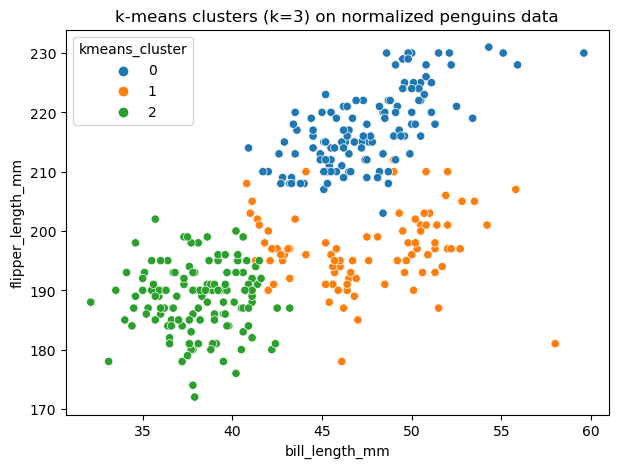

In [20]:
# Adding the kmeans labels to the UNSCALED dataframe so the plots stay in the original units (mm, g)

penguins_cleaned['kmeans_cluster'] = kmeans_labels

plt.figure(figsize=(7, 5))
sns.scatterplot(data=penguins_cleaned, x='bill_length_mm', y='flipper_length_mm',
                hue='kmeans_cluster', palette='tab10')
plt.title('k-means clusters (k=3) on normalized penguins data')
plt.show()

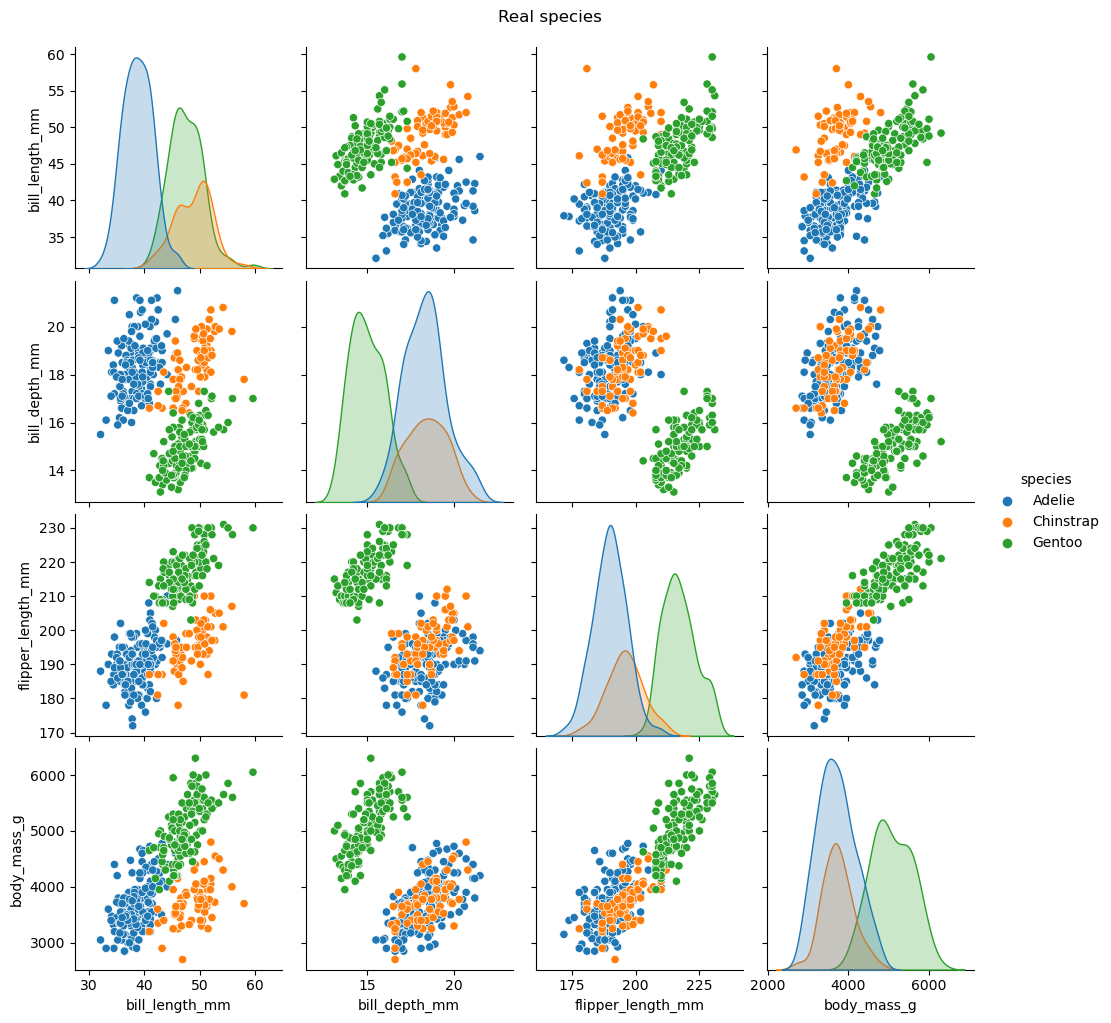

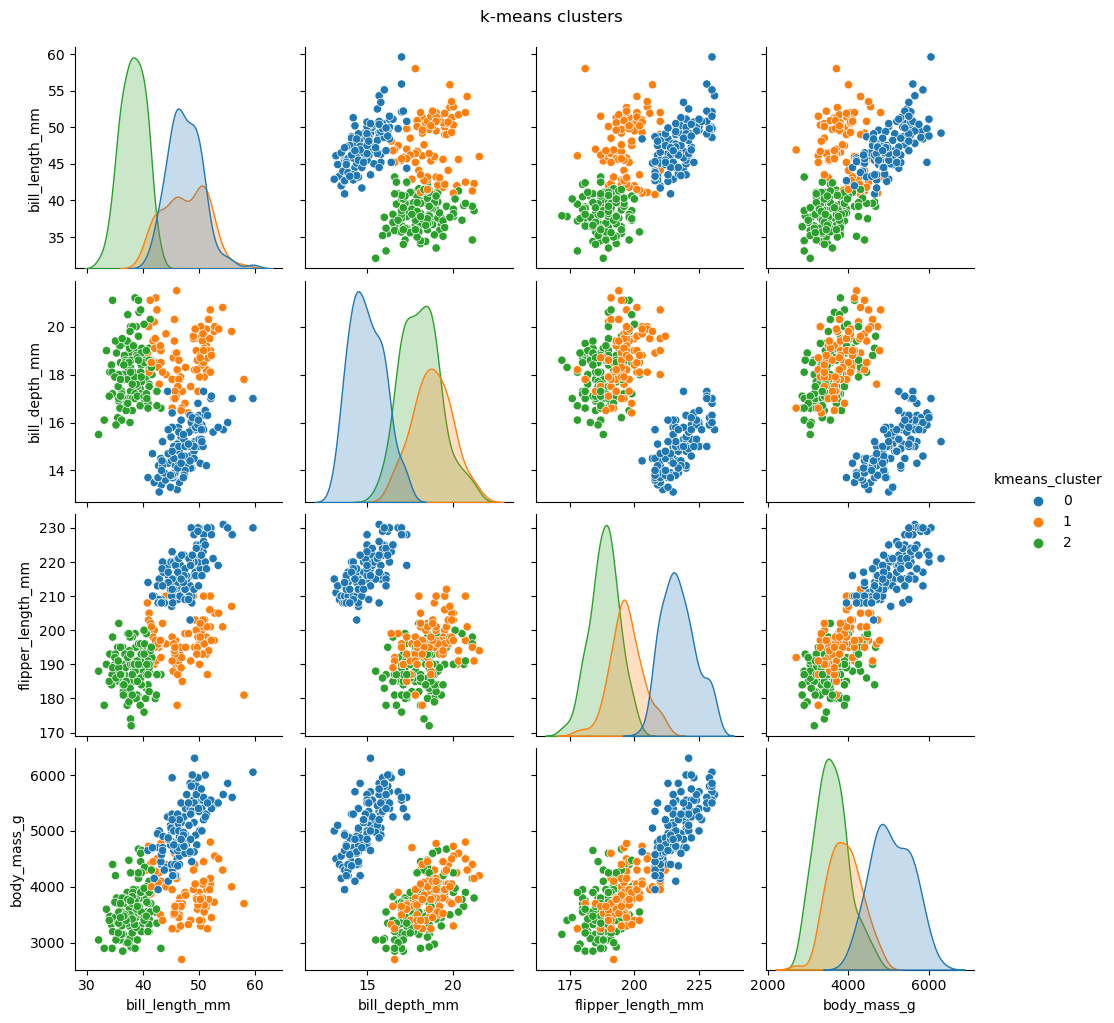

In [21]:
# Adding two pairplots to compare real species vs. k-means clusters
pp1 = sns.pairplot(penguins_cleaned, vars=num_cols, hue='species')
pp1.figure.suptitle('Real species', y=1.02)
plt.show()

pp2 = sns.pairplot(penguins_cleaned, vars=num_cols, hue='kmeans_cluster', palette='tab10')
pp2.figure.suptitle('k-means clusters', y=1.02)
plt.show()

#### (1e) Clusters Comparison

           cluster 0  cluster 1  cluster 2
Adelie             0         24        127
Chinstrap          0         63          5
Gentoo           123          0          0


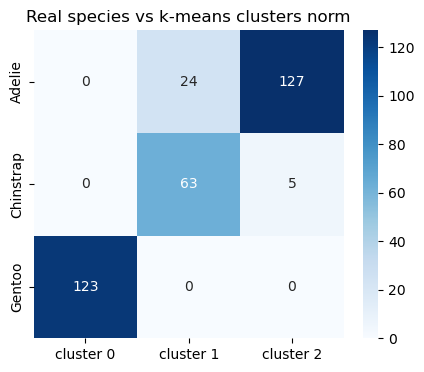

Adjusted Rand score (normalized data): 0.793


In [23]:
# Confusion matrix + adjusted Rand score vs. the real species
# confusion_matrix can't mix text labels (species) with numbers (clusters), 
# so we encode species as 0/1/2 first, using LabelEncoder

le = LabelEncoder()
species_encoded = le.fit_transform(penguins_cleaned['species'])

cm = confusion_matrix(species_encoded, kmeans_labels)   # rows = real species, columns = clusters
cm_df = pd.DataFrame(cm, index=le.classes_, columns=[f'cluster {i}' for i in range(3)])
print(cm_df)

plt.figure(figsize=(5, 4))
sns.heatmap(cm_df, annot=True, fmt='d', cmap='Blues')
plt.title('Real species vs k-means clusters norm')
plt.show()

ars_scaled = adjusted_rand_score(species_encoded, kmeans_labels)
print("Adjusted Rand score (normalized data):", round(ars_scaled, 3))

#### (1f) Discussion

In [25]:
# Running the same k-means on the RAW (unscaled) values, to compare before normalisation vs after

raw_labels = KMeans(n_clusters=3, n_init=10, random_state=42).fit_predict(penguins_cleaned[num_cols])

cm_raw = pd.DataFrame(confusion_matrix(species_encoded, raw_labels),
                      index=le.classes_, columns=[f'cluster {i}' for i in range(3)])
print(cm_raw)
print("Adjusted Rand score (raw data):", round(adjusted_rand_score(species_encoded, raw_labels), 3))

           cluster 0  cluster 1  cluster 2
Adelie           116          0         35
Chinstrap         53          0         15
Gentoo             1         61         61
Adjusted Rand score (raw data): 0.318


In [26]:
# Running a second describe function, using agg, on the original dataset to see statistical info for the species 

penguins_cleaned.groupby('species')[num_cols].agg(['min', 'max', 'mean', 'std']).round(1)

bill_length_mm                  bill_depth_mm                   \
                     min   max  mean  std           min   max  mean  std   
species                                                                    
Adelie              32.1  46.0  38.8  2.7          15.5  21.5  18.3  1.2   
Chinstrap           40.9  58.0  48.8  3.3          16.4  20.8  18.4  1.1   
Gentoo              40.9  59.6  47.5  3.1          13.1  17.3  15.0  1.0   

          flipper_length_mm                    body_mass_g                  \
                        min    max   mean  std         min     max    mean   
species                                                                      
Adelie                172.0  210.0  190.0  6.5      2850.0  4775.0  3700.7   
Chinstrap             178.0  212.0  195.8  7.1      2700.0  4800.0  3733.1   
Gentoo                203.0  231.0  217.2  6.5      3950.0  6300.0  5076.0   

                  
             std  
species           
Adelie     458.6  
Chinstrap  384.3  
Gentoo     504.1

**Does k-means recover the 3 species?** 

Yes, but partly. In the normalised dataset, Gentoo is recovered completely, with all 123 Gentoo penguins landing in one cluster, cluster 0. However Adelie and Chinstrap didn't completely cluster separately. Most Adelie (127) share a cluster with Chinstrap (5), and most Chinstrap (63) share a cluster with Adelie (24). The 0.79 adjusted Rand score implies that the match with the real species is good but not perfect, since 1 is perfect and 0 is random.

**Why Adelie and Chinstrap get mixed up:** Gentoo penguins are much larger, as we can see from the agg details, with longer flippers and heavier bodies, so they sit far from the other two. Adelie and Chinstrap overlap heavily in body size and flipper length, so k-means, which only looks at distance to the nearest centroid, cannot separate them cleanly. In the species pairplot, Adelie and Chinstrap overlap in most panels, and they separate mainly on bill length. 

Normalizing the data also helped a lot. Without it the adjusted Rand score decreases to about 0.31. body_mass_g is in the thousands while bill depth is around 15–20, so on raw data the Euclidean distance is then decided by body mass alone. The clusters split penguins by weight and ignore the bill measurements, which is where Adelie and Chinstrap differ. Normalizing puts all four variables on an equal basis.

---

# **Exercise 2:** Hierarchical clustering + a custom distance function (S1 + S3)

We'll use the small synthetic dataset from the S3 notebook:

```python
import numpy as np
X = np.array([[1, 2], [1, 4], [1, 0], [5, 6], [5, 3], [5, 0]])
```

a) **(control de datos)** Even on a small synthetic array like this one, it's good practice to check for missing values before doing anything else: use `np.isnan(X).any()` to confirm there are none.

b) **(normalization)** Normalize `X` with `StandardScaler` before clustering (even though both coordinates here happen to be on a similar scale, this should always be the default first step for any distance-based method, so that you don't forget it on a real dataset where scales usually differ a lot).

c) **(S1 recap)** Write a plain Python function `euclidean_distance(p1, p2)` **without using numpy or sklearn**, using only a `for` loop over the coordinates, that computes the Euclidean distance between two points (given as lists or tuples). Test it on `euclidean_distance(X[0], X[3])` and check it against `np.linalg.norm(X[0]-X[3])`.

d) Apply **Agglomerative Clustering** with `n_clusters=2` to the **normalized** `X` (as done in the S3 notebook), and plot the **dendrogram** using `scipy.cluster.hierarchy.dendrogram` and `linkage`.

e) Also apply **k-means** with `n_clusters=2` to the same normalized data.

f) Compare the cluster labels obtained by agglomerative clustering and k-means — are they identical for this small dataset? (Print both label arrays, and make a side-by-side scatterplot of the original points colored by each method's labels.)

g) **(S1 recap)** Write a function `cluster_sizes(labels)` that takes an array of cluster labels and returns a **dictionary** with the count of observations per cluster (reuse the dictionary-counting pattern from S1), and apply it to both clusterings.

In [30]:
# Importing the necessary libraries 

import numpy as np
from sklearn.cluster import AgglomerativeClustering, KMeans
from sklearn.preprocessing import StandardScaler
from scipy.cluster.hierarchy import dendrogram, linkage
import matplotlib.pyplot as plt

In [31]:
# Preparing the data 

X = np.array([[1, 2], [1, 4], [1, 0], [5, 6], [5, 3], [5, 0]]) 
X

array([[1, 2],
       [1, 4],
       [1, 0],
       [5, 6],
       [5, 3],
       [5, 0]])

#### (2a) Data Cleaning

In [33]:
# Checking for missing values: 
np.isnan(X).any()

False

#### (2b) Normalization

In [35]:
X_scaled = StandardScaler().fit_transform(X)
print(X_scaled.round(3))

[[-1.    -0.234]
 [-1.     0.701]
 [-1.    -1.168]
 [ 1.     1.635]
 [ 1.     0.234]
 [ 1.    -1.168]]


#### (2c) Euclidean distance function

In [37]:
# Euclidean distance can be calculated as sqrt( (x1-y1)^2 + (x2-y2)^2 + ... )

def euclidean_distance(p1, p2):
    total = 0.0
    for x, y in zip(p1, p2):          # goes through both points coordinate by coordinate
        total += (x - y) ** 2
    return total ** 0.5               # ** 0.5 is the square root, that is raised to power of half

print(round(euclidean_distance(X[0], X[3]), 2))
print(round(np.linalg.norm(X[0] - X[3]), 2))

5.66
5.66


#### (2d) Agglomerative Clustering

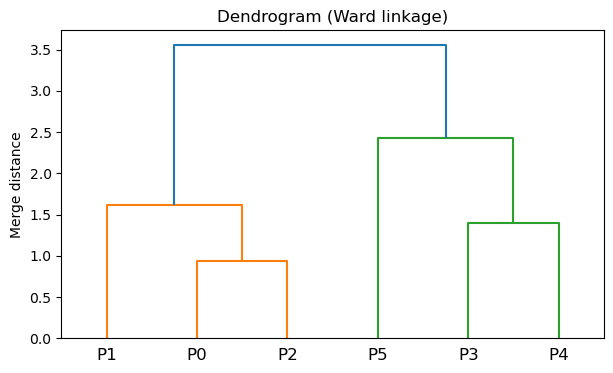

In [39]:
# Agglomerative clustering on the normalized data
agglo_labels = AgglomerativeClustering(n_clusters=2).fit_predict(X_scaled)

# Dendrogram: method='ward' so it matches the clustering above
Z = linkage(X_scaled, method='ward')
plt.figure(figsize=(7, 4))
dendrogram(Z, labels=[f'P{i}' for i in range(len(X))])
plt.title('Dendrogram (Ward linkage)')
plt.ylabel('Merge distance')
plt.show()

#### (2e) k-means on the normalised data

In [41]:
# k-means with 2 clusters on the same normalized data
kmeans_labels = KMeans(n_clusters=2, n_init=10, random_state=42).fit_predict(X_scaled)

#### (2f) Comparing both cluster results 

[1 1 1 0 0 0]
[1 1 1 0 0 0]
Identical arrays? True
Adjusted Rand score between the two: 1.0


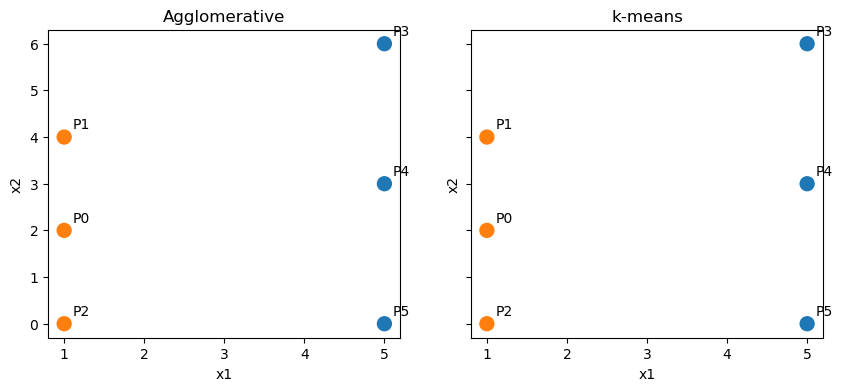

In [43]:
# f) Compare the two label arrays

print(agglo_labels)
print(kmeans_labels)
print("Identical arrays?", np.array_equal(agglo_labels, kmeans_labels))

from sklearn.metrics import adjusted_rand_score
print("Adjusted Rand score between the two:", adjusted_rand_score(agglo_labels, kmeans_labels))

# Side-by-side scatterplot of the original points

fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharex=True, sharey=True)
for ax, labels, title in zip(axes, [agglo_labels, kmeans_labels], ['Agglomerative', 'k-means']):
    ax.scatter(X[:, 0], X[:, 1], c=labels, cmap='tab10', vmin=0, vmax=9, s=100)
    for i, (x, y) in enumerate(X):
        ax.annotate(f'P{i}', (x, y), textcoords='offset points', xytext=(6, 6))
    ax.set_title(title)
    ax.set_xlabel('x1')
    ax.set_ylabel('x2')
plt.show()

The two clusterings are identical as both split the data into the same two groups: P0, P1 and P2 (x = 1) versus P3, P4 and P5 (x = 5). An adjusted Rand score of 1.0 also confirms they are the same partition, with the cluster sizes are 3 and 3 in both.

#### (2g) Cluster_sizes(labels) function

In [46]:
# Count observations per cluster with a dictionary

def cluster_sizes(labels):
    sizes = {}
    for label in labels:
        label = int(label)           
        if label in sizes:
            sizes[label] += 1         # if seen before, add one
        else:
            sizes[label] = 1          # first time: start at one
    return sizes

print(cluster_sizes(agglo_labels))
print(cluster_sizes(kmeans_labels))

{1: 3, 0: 3}
{1: 3, 0: 3}


---

# **Exercise 3:** Choosing the number of clusters with GMM + BIC (S1+S2+S3)

We'll reuse the `diamonds` sample from the S2.1 session:

```python
diamonds = sns.load_dataset('diamonds').sample(1000, random_state=42)
```

a) **(S2 recap)** Select only the numeric columns `carat`, `depth`, `table`, `price` into a new dataframe `diamonds_num`. **Check for missing values** (`.isna().sum()`) and drop any rows with `NaN` if needed, confirming the data is clean afterwards.

b) **(exploración, opcional pero recomendado)** Plot the distribution of `price` (histogram) and mark the mean and mean ± one standard deviation with vertical lines, as done in S2.1 — this helps you see just how skewed and large-scale `price` is compared to the other three variables.

c) **(normalization)** `carat`, `depth`, `table` and `price` are on very different scales (price ranges into the thousands of dollars, while depth/table are percentages around 50–70). **Normalize all four columns with `StandardScaler`** before fitting the GMM — otherwise `price` alone will dominate the covariance structure the model is trying to fit.

d) As done in the S3 notebook, fit a **Gaussian Mixture Model** on the **normalized** data for a range of number of components from 1 to 8, store the **BIC** value for each in a list, and plot BIC vs number of components.

e) Find the number of components that **minimizes** the BIC, and fit the final GMM model with that number of components. Store the predicted cluster labels in `gmm_labels`.

f) Add `gmm_labels` as a new column to your (unscaled, more interpretable) `diamonds_num` and create a **pairplot** (`sns.pairplot`) of `carat`, `depth`, `table`, `price`, colored by `gmm_labels` (`hue`), as done in S2.1. Also make a **jointplot** (`sns.jointplot`) of `carat` vs `price` to zoom into the relationship driving most of the clustering.

g) In a short comment or markdown cell: does the optimal number of clusters found by BIC seem reasonable when you look at the pairplot? Would you have guessed the same number just by eye? Did normalizing the data change the optimal number of components compared to fitting the GMM on the raw values?

In [49]:
import seaborn as sns
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn import mixture
from sklearn.preprocessing import StandardScaler

diamonds = sns.load_dataset('diamonds').sample(1000, random_state=42)

# a) YOUR CODE HERE: select numeric columns into diamonds_num, check missing values, dropna() and confirm it's clean
diamonds_num = None

# b) YOUR CODE HERE: histogram of 'price' with mean and mean +/- std lines


# c) YOUR CODE HERE: normalize the 4 numeric columns with StandardScaler
diamonds_scaled = None

# d) YOUR CODE HERE: fit GMM for n_components = 1..8 on diamonds_scaled, store BIC values, plot BIC vs n_components
bic = []
n_components_range = range(1, 9)


# e) YOUR CODE HERE: find the number of components that minimizes BIC and fit the final GMM
best_n = None
gmm_labels = None

# f) YOUR CODE HERE: add gmm_labels to diamonds_num (unscaled) and make a pairplot + a jointplot (carat vs price)


# g) YOUR CODE HERE (as a comment or markdown cell): interpretation


In [50]:
import seaborn as sns
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn import mixture
from sklearn.preprocessing import StandardScaler

#### (3a) Data Preparation

In [52]:
diamonds = sns.load_dataset('diamonds').sample(1000, random_state=42) 

# Selecting the numeric columns and checking for missing values
num_cols = ['carat', 'depth', 'table', 'price']
diamonds_num = diamonds[num_cols].copy()     

print("Missing values per column:")
print(diamonds_num.isna().sum()) 

Missing values per column:
carat    0
depth    0
table    0
price    0
dtype: int64


In [53]:
diamonds_num.head()

,carat,depth,table,price
1388,0.24,62.1,56.0,559
50052,0.58,60.0,57.0,2201
41645,0.40,62.1,55.0,1238
42377,0.43,60.8,57.0,1304
17244,1.55,62.3,55.0,6901


#### (3b) EDA

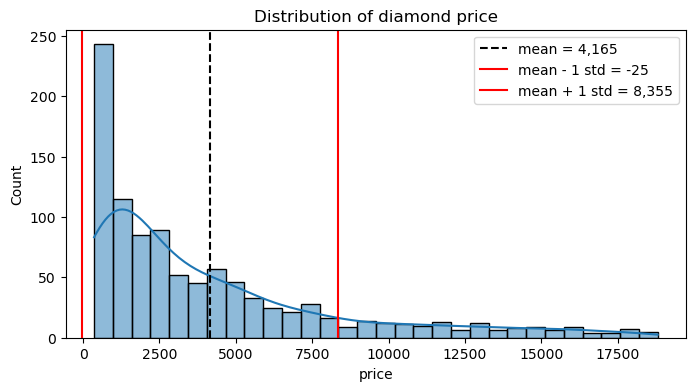

In [55]:
# Histogram of price with mean and mean +/- 1 std
price_mean = diamonds_num['price'].mean()
price_std = diamonds_num['price'].std()

plt.figure(figsize=(8, 4))
sns.histplot(diamonds_num['price'], bins=30, kde=True)
plt.axvline(price_mean, color='k', linestyle='--', label=f'mean = {price_mean:,.0f}')
plt.axvline(price_mean - price_std, color='r', label=f'mean - 1 std = {price_mean - price_std:,.0f}')
plt.axvline(price_mean + price_std, color='r', label=f'mean + 1 std = {price_mean + price_std:,.0f}')
plt.title('Distribution of diamond price')
plt.legend()
plt.show()

#### (3c) Normalization

In [57]:
# Normalizing using (mean 0, std 1)
diamonds_scaled = StandardScaler().fit_transform(diamonds_num)
diamonds_scaled

array([[-1.19910658,  0.24293476, -0.5945033 , -0.86106479],
       [-0.50515554, -1.25622185, -0.16017886, -0.46899303],
       [-0.87254138,  0.24293476, -1.02882775, -0.69893524],
       ...,
       [-0.50515554, -0.47094934, -0.5945033 , -0.58408352],
       [-0.91336203,  0.17154635, -1.02882775, -0.8443504 ],
       [ 0.71946395, -1.47038708,  0.27414559,  1.28267469]])

#### (3d) Fitting a GMM

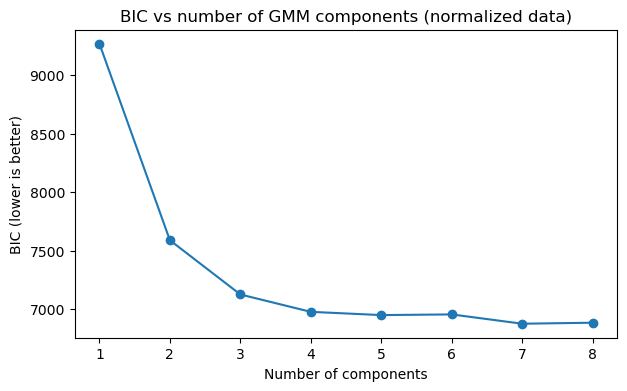

In [59]:
# Fit a GMM for 1-8 components

bic = []
n_components_range = range(1, 9)

for n in n_components_range:
    gmm = mixture.GaussianMixture(n_components=n, covariance_type='full',
                                  n_init=10, random_state=42)   # 10 restarts
    gmm.fit(diamonds_scaled)
    bic.append(gmm.bic(diamonds_scaled))

plt.figure(figsize=(7, 4))
plt.plot(list(n_components_range), bic, marker='o')
plt.xlabel('Number of components')
plt.ylabel('BIC (lower is better)')
plt.title('BIC vs number of GMM components (normalized data)')
plt.show()

#### (3e) Final GMM

In [61]:
# The best model will have the LOWEST BIC
# np.argmin gives a position starting at 0, but our range starts at 1, hence the + 1 

best_n = int(np.argmin(bic)) + 1
print("Best number of components:", best_n)

final_gmm = mixture.GaussianMixture(n_components=best_n, covariance_type='full',
                                    n_init=10, random_state=42).fit(diamonds_scaled)
gmm_labels = final_gmm.predict(diamonds_scaled)

Best number of components: 7


#### (3f) Visualizing and Comparing

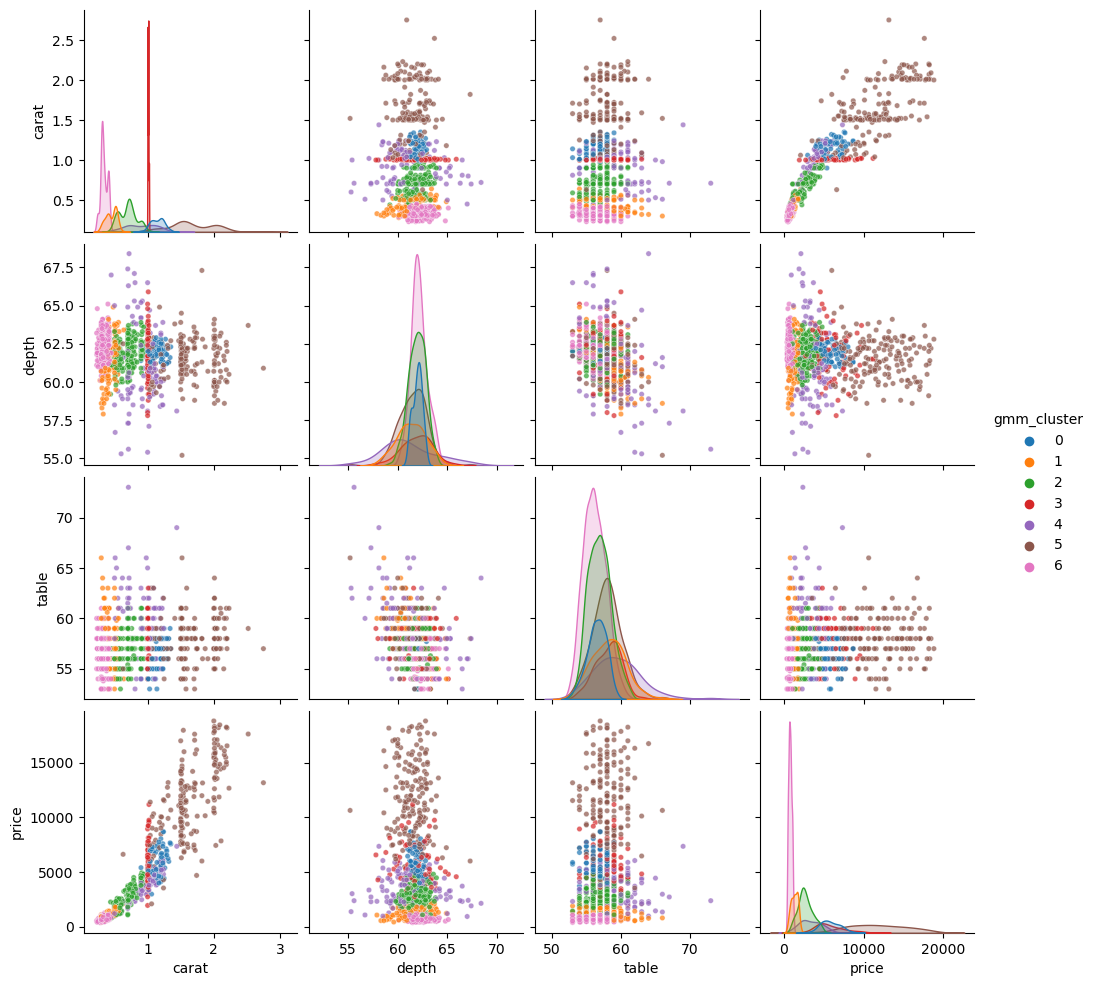

In [63]:
# Adding the gmm labels to the unscaled data so the plots stay in real units 

diamonds_num['gmm_cluster'] = gmm_labels

sns.pairplot(diamonds_num, vars=num_cols, hue='gmm_cluster',
             palette='tab10', plot_kws={'s': 15, 'alpha': 0.7})
plt.show()

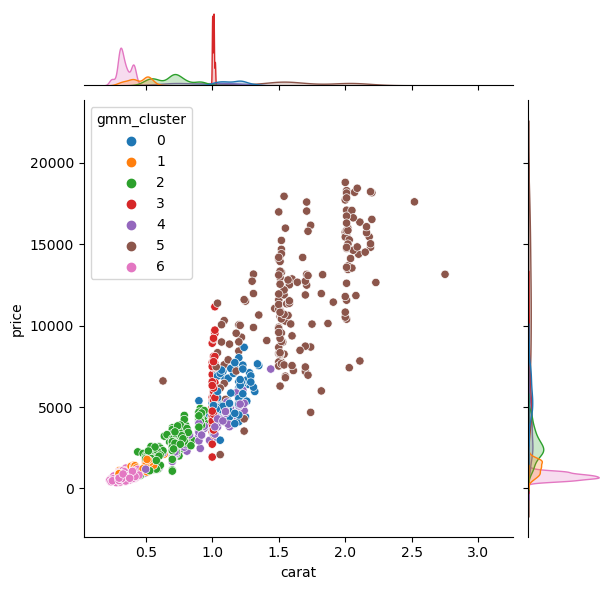

In [64]:
# Focusing on carat vs price to inspect relationships
sns.jointplot(data=diamonds_num, x='carat', y='price', hue='gmm_cluster', palette='tab10')
plt.show()

#### (3g) Discussion

**Is the optimal number reasonable?** 

The BIC drops sharply up to 4 components and then starts flattening. This implies most of the data is captured by 4–5 clusters and the extra ones add little distinction. The BIC minimum is 7 here, but the difference from 4–6 is small.

In the pairplot, the clusters separate mainly along carat and price as small cheap diamonds (around 0.3–0.4 carat), mid-size ones, a very distinct group at 1 carat, and large, expensive stones (1.5–2 carat, 10,000+). Depth and table look almost the same across clusters, except for one cluster that picks up the unusual values (very high table, extreme depth). The 1-carat group appears probably because diamonds are cut and sold at round figure carat weights, which creates spikes in the data, and The GMM turns those into their own components.

Looking at the spread on my own, I would guess fewer clusters. For example I see about 4 broad clusters where points under 1 carat belong to one cluster. 

In [67]:
# Running the same BIC search on the raw (unscaled) data

raw_data = diamonds_num[num_cols].values
bic_raw = []
for n in n_components_range:
    g = mixture.GaussianMixture(n_components=n, covariance_type='full', n_init=10, random_state=42).fit(raw_data)
    bic_raw.append(g.bic(raw_data))

best_n_raw = int(np.argmin(bic_raw)) + 1
print("Best n (normalized):", best_n, "| Best n (raw):", best_n_raw)

# Optional: cluster profiles in real units, to help the interpretation
print(diamonds_num.groupby('gmm_cluster')[num_cols].mean().round(2))

Best n (normalized): 7 | Best n (raw): 5
             carat  depth  table     price
gmm_cluster                               
0             1.14  61.96  56.48   5785.61
1             0.45  61.36  58.21   1291.33
2             0.70  61.91  56.89   2664.92
3             1.01  61.89  58.11   5735.13
4             0.90  61.14  59.47   3367.70
5             1.66  61.50  58.00  11736.50
6             0.34  62.13  56.18    758.02


**Did normalizing change the optimum number of components?** 

Yes. On the raw data, BIC chose 5 components, and chose 7 on the normalized data. In raw data, price has the largest variance, so the model is mostly focusing on it and describing it. After normalizing, carat, depth and table count equally, which gives the model more structure to fit and increases the best count.